# Generate source-level connectomes from tractograms

In this tutorial, we show how to generate a source-level connectome from an individual subject's tractogram. The connectome is used to define its connectome spectrum transform, which is an essential part of the CSET method. <br>

Tractography is a 3D modeling technique that visualizes nerve tracts based on data from diffusion MRI. The output is typically displayed as two- or three-dimensional images known as tractograms, which illustrate the physical connections between brain regions. These connections can be represented as a graph, called a **structural connectome**, where nodes correspond to brain regions and edges represent structural links. In our context, brain regions are modeled as dipoles in the source model. To determine which dipoles are connected, we apply a nearest-neighbor algorithm to the endpoints of the nerve tracts. Each tract thereby identifies a connection between specific dipoles. <br>

In more detail, the following steps are applied:
1. **Filter out non-credible tracts** to eliminate spurious or anatomically implausible connections.
2. **Associate tract endpoints with dipoles** using a nearest-neighbor algorithm.
3. **Smooth the results** to generate a high-resolution connectome.
4. **Add local neighbor connections** to account for interactions within gray matter.
5. **Assign informative weights** to the connections based on tract-specific properties.

(J'aimerai bien un petit shéma la)

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [1]:
# imports
import mindmap as mm
import numpy as np
import nibabel as nib
import pyvista as pv

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
src = dm.load(sub, "fwd", desc="sim")["src"]
tracto = dm.load(sub, "tractogram")
t12diff = dm.load(sub, "t12diff")
ctx = dm.load(sub, "ctx", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")

## 🧬 - Data Processing

Compute connectivity matrix from tractogram.

In [2]:
# prune tractogram (delete none-gray matter endings)
pruned_tracto, deleted_tracto = mm.anatomy.tractogram.prune_tracts(tracto, ctx, t12diff, return_pruned=True)

# build (length) connectivity matrix
# radius=2.5mm: connects each streamline endpoint to every dipole within reach
# instead of only the single nearest one, mass-conserving (normalized by how many
# dipoles are in reach). Grounded in this subject's own measured endpoint scatter
# at the current source-space resolution: median distance-to-nearest-dipole 1.36mm,
# 90th pct 1.96mm, 99th pct 2.49mm -- 2.5mm keeps orphaned streamlines (no dipole
# in reach) under 1%, without being so wide it blurs across unrelated structure.
con_tracto = mm.analysis.connectivity.connectome_from_tracts(
    pruned_tracto, src, t12diff, ras2tkras, lengths=True, radius=4,
)

Add geometry connections.

In [3]:
# maximum_dist=15mm: unchanged -- at the current resolution this only excludes ~1%
# of true (Euclidean) nearest-neighbor pairs from being connected (down from ~6.4%
# at the old, coarser resolution), so it's well justified and also matches typical
# U-fiber length scales (~5-30mm) from the literature.
# maximum_neigh=8: was 3, but each dipole now has ~88 candidates within 15mm
# geodesic distance (up from ~35 at the old resolution, since dipole density
# roughly tripled) -- 3 would now be a much more aggressive relative thinning
# than before. Scaled up to keep similar relative local coverage; a softer,
# less rigorously-grounded choice than the radius/maximum_dist above.
con_geom = mm.analysis.connectivity.connectome_from_geometry(
    src,
    maximum_dist = 15,
    maximum_neigh = 3,
    weights = True,
)

# fuse connectomes: WM (tractography) takes priority over GM (local geometry)
# wherever both exist, since a real streamline-derived connection should never be
# silently discarded in favor of a generic local-distance proxy. GM only fills in
# where WM has nothing.
con = con_tracto.copy()
fill_idx = np.argwhere((con_geom > 0) & (con_tracto == 0))
con[fill_idx[:,0], fill_idx[:,1]] = con_geom[fill_idx[:,0], fill_idx[:,1]]

Edge provenance.

In [4]:
# Edge provenance: how much of the final connectome is real streamline-derived
# structure vs. the generic local-geometry fallback filling in where
# tractography found nothing.
iu = np.triu_indices(len(con), k=1)
wm_mask = (con_tracto > 0)[iu]
geom_mask = (con_geom > 0)[iu]

wm_only = wm_mask & ~geom_mask
geom_only = geom_mask & ~wm_mask
both = wm_mask & geom_mask

n_total = (wm_mask | geom_mask).sum()
print(f"Total edges in final connectome: {n_total}")
print(f"WM tractography only: {wm_only.sum()} ({wm_only.sum()/n_total*100:.1f} %)")
print(f"Local geometry only:  {geom_only.sum()} ({geom_only.sum()/n_total*100:.1f} %)")
print(f"Both WM and geometry: {both.sum()} ({both.sum()/n_total*100:.1f} %)")

Total edges in final connectome: 218319
WM tractography only: 209425 (95.9 %)
Local geometry only:  1150 (0.5 %)
Both WM and geometry: 7744 (3.5 %)


## 📊 - Visualization
Source Space - Diffusion Space alignment

In [5]:
# Gray matter (voxel -> RAS)
gm_points = np.argwhere(ctx.get_fdata()>0)
gm_points = nib.affines.apply_affine(ctx.affine, gm_points)

# Dipoles (tkras -> voxel -> RAS)
dipoles = mm.anatomy.source_space.get_dipole_positions(src)*1000    # converted to [mm]
dipoles = nib.affines.apply_affine(np.linalg.inv(ras2tkras), dipoles)

# Diffusion tracts (diffusion -> voxel -> RAS)
dwi_points = np.vstack(mm.anatomy.tractogram.tract_endpoints(tracto))
#affine = data["ctx"].affine @ np.linalg.inv(data["t12diff"]) @ np.linalg.inv(data["tracto"].affine)        # what I excpected but it doesn't work, check with Yasser
#dwi_points = nib.affines.apply_affine(affine, dwi_points)
dwi_points = mm.anatomy.align_diffusion2subject(dwi_points, t12diff)

p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(dipoles, color="black", render_points_as_spheres=True, point_size=5, label="dipoles")
p.add_mesh(dwi_points, color="green", render_points_as_spheres=True, point_size=3, label="dwi")
p.show()

Widget(value='<iframe src="http://localhost:36719/index.html?ui=P_0x7b0f0667a0d0_0&reconnect=auto" class="pyvi…

Pruning results.

In [6]:
# extract endpoints
pruned_points  = np.vstack(mm.anatomy.tractogram.tract_endpoints(pruned_tracto))
deleted_points = np.vstack(mm.anatomy.tractogram.tract_endpoints(deleted_tracto))

percent = len(deleted_points)/(len(deleted_points)+len(pruned_points))*100
print(f"Number of tracts removed: {percent:.1f} %")

# align points
pruned_points = mm.anatomy.align_diffusion2subject(pruned_points, t12diff)
deleted_points = mm.anatomy.align_diffusion2subject(deleted_points, t12diff)

# plot
p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(pruned_points, color="green", render_points_as_spheres=True, point_size=3, label="remaining streamline endpoints")
p.add_mesh(deleted_points, color="red", render_points_as_spheres=True, point_size=3, label="deleted streamline endpoints")
p.show()

Number of tracts removed: 15.1 %


Widget(value='<iframe src="http://localhost:36719/index.html?ui=P_0x7b0f0c4409d0_1&reconnect=auto" class="pyvi…

Tractogram only connectome.

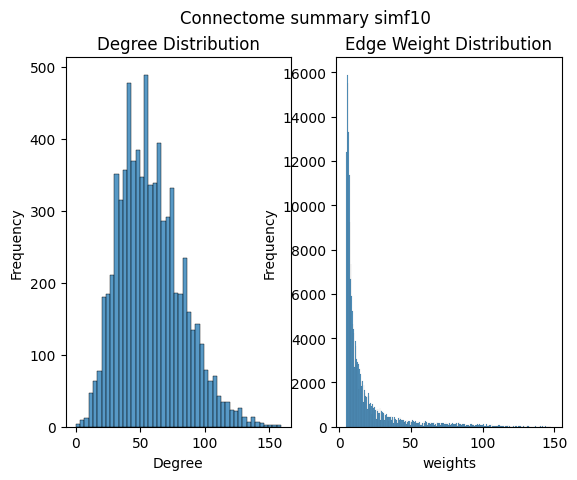

In [7]:
mm.viz.plot_con_summary(con_tracto, title="Connectome summary simf10")
#mm.head.print_connectome_summary(conn)

In [ ]:
isolated_nodes = np.argwhere(np.sum(con_tracto>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes with tracts only: {int(targets.sum())}")

isolated_nodes = np.argwhere(np.sum(con>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes in final connectome: {int(targets.sum())}")


Number of isolated nodes with tracts only: 3
Number of isolated nodes in final connectome: 0


Final Connectome.

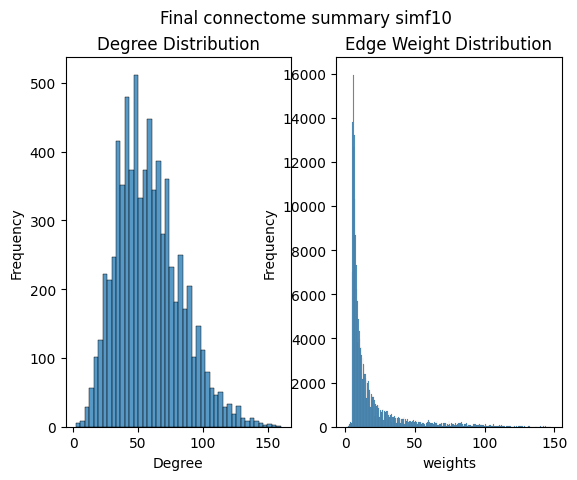

In [9]:
mm.viz.plot_con_summary(con, title="Final connectome summary simf10")

Adjacency matrix.

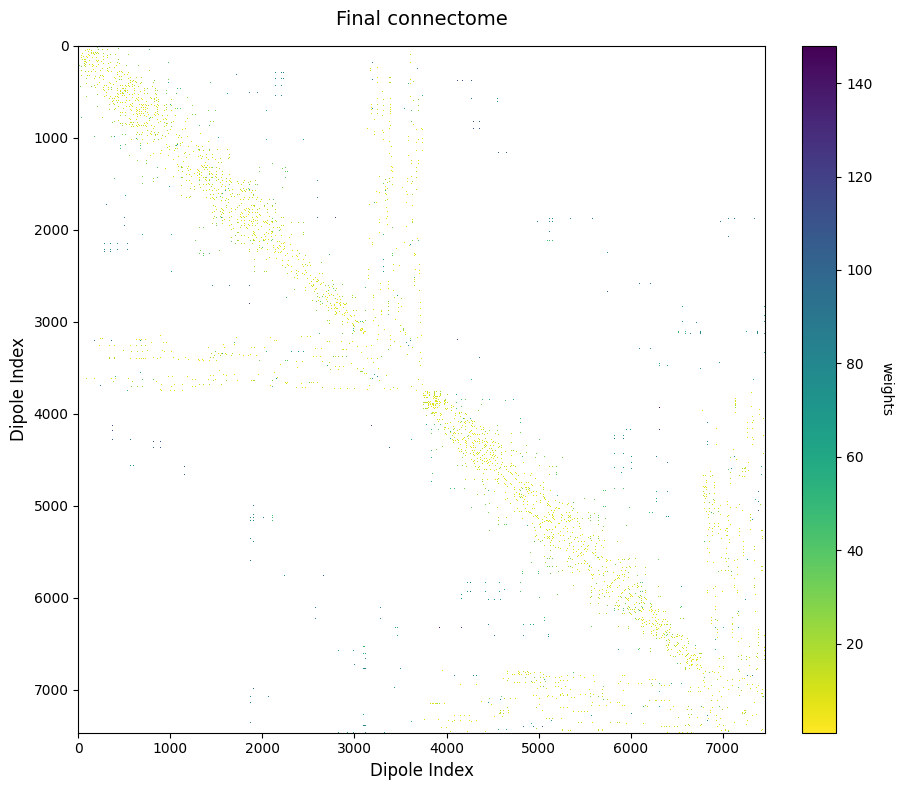

In [10]:
mm.viz.plot_adj_matrix(con, title="Final connectome")

## 📏 - Validation metrics

No normative dipole-resolution connectome exists to compare against, so the statistics below are a descriptive baseline for `simf10` rather than a pass/fail check against an established target -- treat this as the first reference point, to compare future subjects (or future resolution/radius/neighbor-count choices) against, rather than an absolute one. See `mindmap.analysis.connectivity.process`'s module docstring for the literature and expected direction of each metric.

In [11]:
import matplotlib.pyplot as plt

# Validation metrics on the final (WM + geometry) connectome. n_null=10
# (not the default 20) to keep this tutorial's runtime reasonable at
# dipole resolution -- increase for a less noisy null estimate.
n_dipoles = mm.anatomy.source_space.get_ndipole(src)
print(f"n_dipoles: {n_dipoles}")
print(f"density: {mm.analysis.connectivity.density(con)*100:.3f} %")

sw = mm.analysis.connectivity.small_world_sigma(con, n_null=10, seed=0)
print(f"small-world sigma: {sw['sigma']:.3f}  (C={sw['C']:.3f} vs C_null={sw['C_null']:.3f}, "
      f"L={sw['L']:.3f} vs L_null={sw['L_null']:.3f})")

mod = mm.analysis.connectivity.modularity(con, seed=0)
print(f"modularity: Q={mod['q']:.3f}, {mod['n_communities']} communities")

hemi = mm.analysis.connectivity.hemispheric_symmetry_from_source_space(con, src)
print(f"hemispheric symmetry: r={hemi['r']:.3f}  (mirror-match error: "
      f"mean={hemi['match_dist_mean']:.2f}mm, max={hemi['match_dist_max']:.2f}mm)")

edr = mm.analysis.connectivity.distance_decay_fit_from_source_space(con, src)
print(f"distance-decay (EDR): lambda={edr['lambda_']:.4f} /mm, r2={edr['r2']:.3f}")

n_dipoles: 7465
density: 0.784 %
small-world sigma: 27.362  (C=0.462 vs C_null=0.011, L=4.172 vs L_null=2.602)
modularity: Q=0.766, 13 communities
hemispheric symmetry: r=0.305  (mirror-match error: mean=2.85mm, max=16.36mm)
distance-decay (EDR): lambda=0.0966 /mm, r2=0.406


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/bct/algorithms/core.py:515: RuntimeWarning: invalid value encountered in scalar divide
  R[k] = Ek[k] / (Nk[k] * (Nk[k] - 1))
/home/nino/Code/mindmap/mindmap/core/metric.py:890: RuntimeWarning: Mean of empty slice
  R_null_mean = np.nanmean(R_null, axis=0)


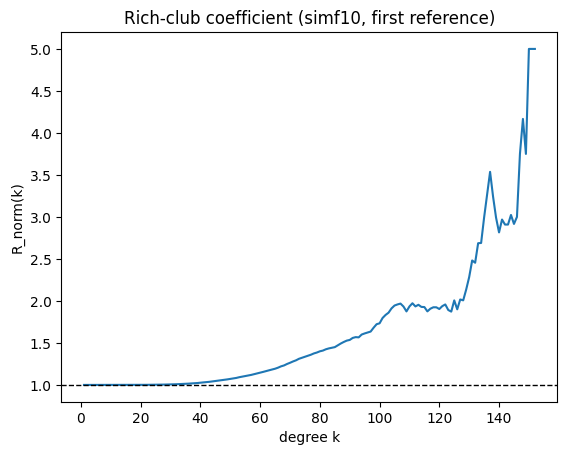

In [12]:
# Rich-club: are high-degree dipoles more densely interconnected than a
# degree-matched null? R_norm(k) > 1 over a range of k is the signature.
rc = mm.analysis.connectivity.rich_club_curve(con, n_null=10, seed=0)

plt.figure()
plt.plot(rc["k"], rc["R_norm"])
plt.axhline(1.0, color="black", linestyle="--", linewidth=1)
plt.xlabel("degree k")
plt.ylabel("R_norm(k)")
plt.title("Rich-club coefficient (simf10, first reference)")
plt.show()

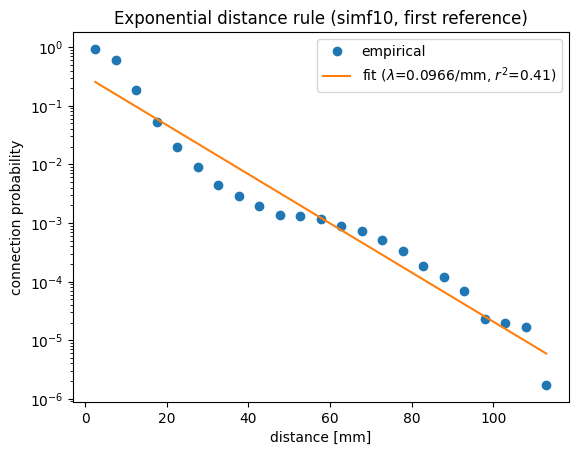

In [13]:
# Exponential distance rule (EDR) fit: connection probability vs. distance.
# Visual check for the log-linear fit computed above.
plt.figure()
valid = np.isfinite(edr["bin_prob"]) & (edr["bin_prob"] > 0)
plt.semilogy(edr["bin_centers"][valid], edr["bin_prob"][valid], "o", label="empirical")

fit = edr["c"] * np.exp(-edr["lambda_"] * edr["bin_centers"])
plt.semilogy(edr["bin_centers"][valid], fit[valid], "-", label=f"fit ($\\lambda$={edr['lambda_']:.4f}/mm, $r^2$={edr['r2']:.2f})")

plt.xlabel("distance [mm]")
plt.ylabel("connection probability")
plt.legend()
plt.title("Exponential distance rule (simf10, first reference)")
plt.show()